# Bài 8: Phân cụm K-Means
**Học máy ứng dụng — Trường Đại học Văn Lang, Khoa Công nghệ Thông tin**

Lời giải theo `Lab08_KMeans.pdf` của ThS. Nguyễn Thái Anh. Phần A gồm **5 bước thực hành**;
phần B gồm **6 bài tập**, kèm giải thích, kiểm chứng và hình minh họa như Lab5.

**Dữ liệu:** `khach_hang.csv` (210 khách), `hai_vang_trang.csv`, ảnh china.jpg và load_digits có sẵn trong scikit-learn.

**Cách chạy:** giải nén gói dữ liệu của lab để có `data/` cạnh notebook, rồi chọn
**Restart Kernel and Run All Cells**. Có thể đặt CSV trực tiếp cạnh notebook. Mở Jupyter từ
gốc repo hoặc thư mục lab đều được. Kết quả được nhúng trong notebook, hình lưu thêm vào `images/`.

**Cài thư viện:** `pip install numpy pandas matplotlib scikit-learn jupyter`.
Các bộ dữ liệu đóng gói trong scikit-learn không cần tải mạng. CSV/PDF/ZIP không đưa lên GitHub.

## 0. Chuẩn bị môi trường

Với thí nghiệm phân loại, chia 75% học / 25% kiểm tra với `random_state=17`, `stratify=y`, giống đề.
Chuẩn hoá được đặt trong pipeline để chỉ học thống kê từ từng tập học của CV.
Chọn tham số hoặc ngưỡng bằng tập học; tập kiểm tra dùng báo cáo các thí nghiệm đã định trong đề.
Vì cùng tập kiểm tra được dùng nhiều lần trong bài thực hành, không xem các kết quả là đánh giá
độc lập cho một hệ thống đã được lựa chọn sau nhiều thí nghiệm.

Lần kiểm tra này giới hạn BLAS/OpenMP ở 1 luồng để giảm dao động và chi phí chạy trên dữ liệu nhỏ; môi trường nhiều luồng có thể cho chênh lệch thời gian và sai số tối ưu số học.

Riêng phân cụm không chia tập theo nhãn: silhouette đánh giá cấu trúc trên dữ liệu phân khúc; nhãn vầng trăng/chữ số chỉ dùng phân tích hậu nghiệm.

In [1]:
from pathlib import Path
from time import perf_counter
import platform
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.datasets import load_digits
from sklearn.exceptions import ConvergenceWarning
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

THU_MUC_LAB = Path('08. K-Means') if Path('08. K-Means').is_dir() else Path('.')
THU_MUC_ANH = THU_MUC_LAB / 'images'
THU_MUC_ANH.mkdir(exist_ok=True)


def doc_csv(ten, cot_bat_buoc):
    for p in (THU_MUC_LAB / 'data' / ten, THU_MUC_LAB / ten):
        if p.is_file():
            df = pd.read_csv(p)
            assert set(cot_bat_buoc).issubset(df.columns), f'Sai cột trong {ten}'
            assert len(df) > 0 and np.isfinite(df[cot_bat_buoc].to_numpy(dtype=float)).all(), ten
            print(f'{ten}: {df.shape[0]} dòng, {df.shape[1]} cột; không thiếu giá trị ở cột dùng')
            return df
    raise FileNotFoundError(f'Thiếu {ten}: hãy giải nén gói dữ liệu vào {THU_MUC_LAB}/data/.')


def chia(X, y):
    return train_test_split(X, y, test_size=0.25, random_state=17, stratify=y)


def luu_hinh(ten):
    plt.savefig(THU_MUC_ANH / ten, dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()


def ve_bien(ax, mo_hinh, X, y, tieu_de):
    a = np.asarray(X)
    le = np.maximum(np.ptp(a, axis=0)*0.08, 0.1)
    xx, yy = np.meshgrid(np.linspace(a[:, 0].min()-le[0], a[:, 0].max()+le[0], 160),
                         np.linspace(a[:, 1].min()-le[1], a[:, 1].max()+le[1], 150))
    luoi = np.c_[xx.ravel(), yy.ravel()]
    if isinstance(X, pd.DataFrame):
        luoi = pd.DataFrame(luoi, columns=X.columns)
    zz = mo_hinh.predict(luoi).reshape(xx.shape)
    ax.contourf(xx, yy, zz, levels=[-0.5, 0.5, 1.5], colors=['#fed7d7', '#c3dafe'], alpha=0.8)
    ax.scatter(a[:, 0], a[:, 1], c=y, cmap='coolwarm_r', s=17, edgecolors='white', linewidths=0.3)
    ax.set_title(tieu_de)
    ax.set_xlabel(X.columns[0] if isinstance(X, pd.DataFrame) else 'x1')
    ax.set_ylabel(X.columns[1] if isinstance(X, pd.DataFrame) else 'x2')


plt.rcParams.update({'figure.figsize': (8, 5), 'figure.dpi': 110,
                     'font.family': 'DejaVu Sans', 'axes.grid': True, 'grid.alpha': 0.25})
print('Python', platform.python_version(), '| NumPy', np.__version__, '| pandas', pd.__version__)
print('scikit-learn', sklearn.__version__, '| matplotlib', plt.matplotlib.__version__)

Python 3.11.9 | NumPy 1.26.4 | pandas 2.3.3
scikit-learn 1.8.0 | matplotlib 3.10.8


---
# Phần A — Bài thực hành
## Bước 1 — Tự viết K-Means (Mục 2, `k1`)

Đây là **học không giám sát**: không chia train/test theo nhãn để phân khúc 210 khách. Nhãn thật
vầng trăng/chữ số chỉ được dùng **sau phân cụm** để phân tích, không dùng để fit hay chọn tâm.

Lặp hai bước: gán mỗi điểm cho tâm gần nhất, rồi dời tâm về trung bình của cụm. Inertia là tổng
bình phương khoảng cách đến tâm của từng điểm; không phải accuracy và có đơn vị phụ thuộc thang đo.
Hàm dưới giữ tâm cũ nếu một cụm rỗng để tránh NaN; nếu hòa khoảng cách, `argmin` chọn tâm đầu.

Vòng 1 tâm: [[1.0, 1.0], [1.5, 2.0]] ; inertia: 84.75
  Cụm 0 : A
  Cụm 1 : B,C,D,E,F,G
Vòng 2 tâm: [[1.0, 1.0], [3.5, 4.583]] ; inertia: 11.2847
  Cụm 0 : A,B
  Cụm 1 : C,D,E,F,G
Vòng 3 tâm: [[1.25, 1.5], [3.9, 5.1]] ; inertia: 8.525
  Cụm 0 : A,B
  Cụm 1 : C,D,E,F,G
Tâm cuối: [[1.25 1.5 ]
 [3.9  5.1 ]] ; inertia tự tính: 8.525 ; sklearn: 8.525


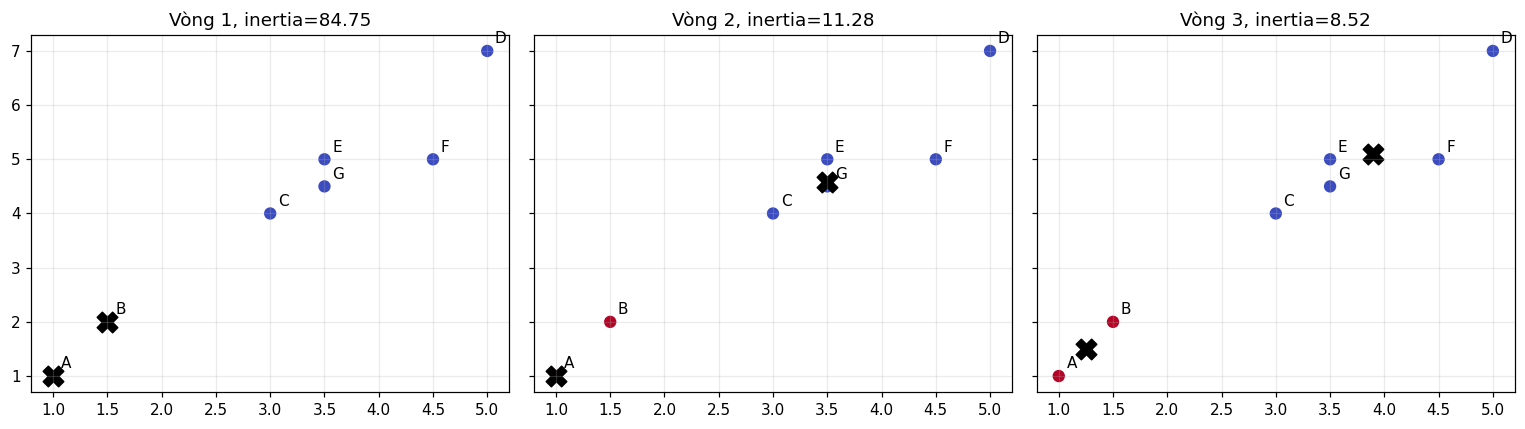

In [2]:
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score
from sklearn.datasets import load_sample_image

P=np.array([[1.,1.],[1.5,2.],[3.,4.],[5.,7.],[3.5,5.],[4.5,5.],[3.5,4.5]])
TEN=np.array(list('ABCDEFG'))


def k_means(X,tam,so_vong_toi_da=100):
    X=np.asarray(X,dtype=float); tam=np.array(tam,dtype=float,copy=True)
    if X.ndim!=2 or tam.ndim!=2 or X.shape[1]!=tam.shape[1] or not len(tam) or not len(X):
        raise ValueError('Dữ liệu và tâm phải là các ma trận không rỗng, cùng số đặc trưng.')
    if so_vong_toi_da<1 or not np.isfinite(X).all() or not np.isfinite(tam).all():
        raise ValueError('Cần số vòng dương và dữ liệu hữu hạn.')
    lich_su=[]
    for vong in range(1,so_vong_toi_da+1):
        kc2=((X[:,None,:]-tam[None,:,:])**2).sum(axis=2)
        nhan=kc2.argmin(axis=1)
        lich_su.append({'vong':vong,'tam':tam.copy(),'nhan':nhan.copy(),
                        'inertia':float(kc2[np.arange(len(X)),nhan].sum())})
        tam_moi=tam.copy()
        for k in range(len(tam)):
            if (nhan==k).any():
                tam_moi[k]=X[nhan==k].mean(axis=0)
        if np.allclose(tam_moi,tam,atol=1e-8,rtol=0):
            tam=tam_moi; break
        tam=tam_moi
    # Gán lại để nhãn luôn tương ứng tâm trả về, kể cả khi hết số vòng.
    nhan=((X[:,None,:]-tam[None,:,:])**2).sum(axis=2).argmin(axis=1)
    return tam,nhan,lich_su


tam_tay,nhan_tay,lich_su=k_means(P,P[[0,1]])
for r in lich_su:
    print('Vòng',r['vong'],'tâm:',r['tam'].round(3).tolist(),'; inertia:',round(r['inertia'],4))
    for k in range(2): print('  Cụm',k,':',','.join(TEN[r['nhan']==k]))
inertia_tay=((P-tam_tay[nhan_tay])**2).sum()
km_tay=KMeans(n_clusters=2,init=P[[0,1]],n_init=1,random_state=0).fit(P)
print('Tâm cuối:',tam_tay,'; inertia tự tính:',inertia_tay,'; sklearn:',km_tay.inertia_)
assert np.isclose(inertia_tay,km_tay.inertia_) and np.isclose(inertia_tay,8.525)
assert np.all(np.diff([r['inertia'] for r in lich_su])<=1e-10)
# Kiểm chứng nhánh xử lý cụm rỗng bằng hai tâm trùng nhau.
tam_rong,_,_=k_means(P,np.vstack([P[0],P[0]])); assert np.isfinite(tam_rong).all()
fig,axes=plt.subplots(1,len(lich_su),figsize=(14,4),sharex=True,sharey=True)
for ax,r in zip(np.atleast_1d(axes),lich_su):
    ax.scatter(P[:,0],P[:,1],c=r['nhan'],cmap='coolwarm_r',s=50)
    ax.scatter(r['tam'][:,0],r['tam'][:,1],marker='X',s=180,c='black')
    for ten,p in zip(TEN,P): ax.annotate(ten,p,xytext=(5,5),textcoords='offset points')
    ax.set_title(f"Vòng {r['vong']}, inertia={r['inertia']:.2f}")
plt.tight_layout(); luu_hinh('hinh1_tu_viet_kmeans.png')

**Nhận xét từ lần chạy đã kiểm tra:** Dừng sau **3 vòng**, tâm (1.25,1.50) và (3.90,5.10); inertia **8.5250**, đúng bằng sklearn. Cụm A,B tách khỏi C,D,E,F,G. Nhánh cụm rỗng cũng đã được kiểm chứng không tạo NaN.

**Giải thích:** inertia không tăng qua các vòng, nhưng thuật toán chỉ tìm nghiệm cục bộ theo
khởi tạo. Kết quả trùng sklearn khi cho cùng hai tâm đầu, không có nghĩa mọi khởi tạo đều giống.

## Bước 2 — Phân khúc khách hàng (Mục 3, `k2`)

Chuẩn hoá thu nhập và điểm chi tiêu, K=5, n_init=10, random_state=0. Đổi tâm về đơn vị gốc để
đọc ý nghĩa; tuổi chỉ để thống kê hậu nghiệm, chưa dùng làm đặc trưng ở bước này.

khach_hang.csv: 210 dòng, 3 cột; không thiếu giá trị ở cột dùng


,tuoi,thu_nhap,diem_chi_tieu
count,210.00,210.00,210.00
mean,37.62,18.52,49.90
std,10.29,9.78,26.82
min,18.00,3.00,7.00
25%,30.00,8.83,22.00
50%,39.00,17.40,49.00
75%,46.00,28.58,77.00
max,62.00,35.50,99.00


,thu_nhap,diem_chi_tieu,so_khach,tuoi_tb
0,7.48,80.20,35,24.94
1,30.13,19.97,35,42.86
2,17.39,49.30,60,40.45
3,8.04,18.85,40,44.88
4,30.21,81.53,40,32.62


Inertia: 23.01674878194891


,thu_nhap,diem_chi_tieu,cum
0,29.0,85,4
1,9.0,75,0


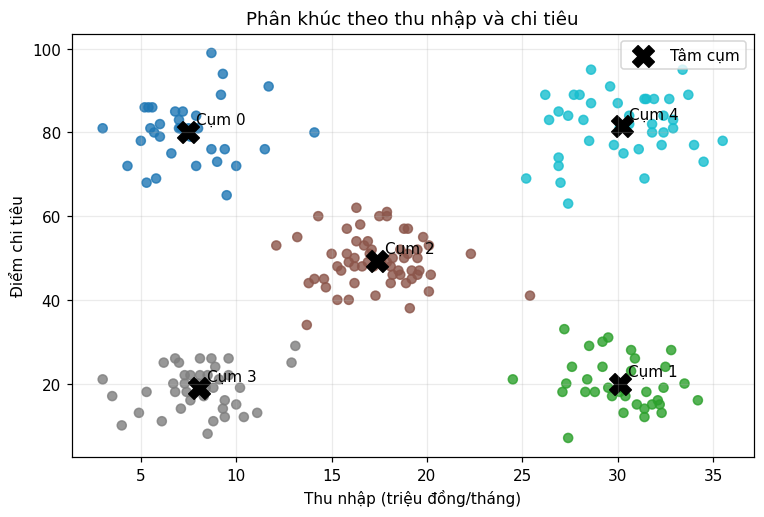

In [3]:
khach=doc_csv('khach_hang.csv',['tuoi','thu_nhap','diem_chi_tieu'])
display(khach.describe().round(2))
cot=['thu_nhap','diem_chi_tieu']; X=khach[cot]
sc=StandardScaler().fit(X); Xs=sc.transform(X)
km5=KMeans(n_clusters=5,n_init=10,random_state=0).fit(Xs)
tam_goc=pd.DataFrame(sc.inverse_transform(km5.cluster_centers_),columns=cot)
tam_goc['so_khach']=np.bincount(km5.labels_,minlength=5)
tam_goc['tuoi_tb']=khach.assign(cum=km5.labels_).groupby('cum')['tuoi'].mean()
display(tam_goc.round(2)); print('Inertia:',km5.inertia_)
khach_moi=pd.DataFrame({'thu_nhap':[29.,9.],'diem_chi_tieu':[85,75]})
display(khach_moi.assign(cum=km5.predict(sc.transform(khach_moi))))
plt.figure()
plt.scatter(X['thu_nhap'],X['diem_chi_tieu'],c=km5.labels_,cmap='tab10',s=35,alpha=.8)
plt.scatter(tam_goc['thu_nhap'],tam_goc['diem_chi_tieu'],marker='X',s=200,c='black',label='Tâm cụm')
for i,r in tam_goc.iterrows(): plt.annotate(f'Cụm {i}',(r['thu_nhap'],r['diem_chi_tieu']),xytext=(5,5),textcoords='offset points')
plt.xlabel('Thu nhập (triệu đồng/tháng)'); plt.ylabel('Điểm chi tiêu'); plt.legend()
plt.title('Phân khúc theo thu nhập và chi tiêu'); luu_hinh('hinh2_phan_khuc_khach.png')

**Nhận xét từ lần chạy đã kiểm tra:** Năm nhóm theo (thu nhập, điểm chi tiêu): thấp/cao **35 khách**, cao/thấp **35**, trung bình **60**, thấp/thấp **40**, cao/cao **40**. Hai khách mới (29,85) vào nhóm cao/cao, (9,75) vào nhóm thấp/cao.

**Diễn giải:** đặt tên nhóm từ tọa độ tâm (thu nhập cao/thấp, chi tiêu cao/thấp, nhóm trung bình),
không suy ý nghĩa từ mã số cụm. Mã 0–4 chỉ là tên tùy ý, có thể đổi thứ tự giữa các lần khởi tạo.
Các gợi ý kinh doanh là giả thuyết cần kiểm chứng, không suy ra từ tuổi trung bình rằng mọi thành
viên đều cùng tuổi hoặc cùng hành vi.

## Bước 3 — Chọn K bằng khuỷu tay và silhouette (Mục 4, `k3`)

Với mỗi điểm, a là khoảng cách trung bình tới các điểm khác cùng cụm; b là trung bình khoảng
cách nhỏ nhất tới một cụm khác. $s=(b-a)/\max(a,b)$, trong [-1,1]. Silhouette không xác định cho
K=1; inertia luôn có xu hướng giảm khi tăng K, nên không chọn K bằng giá trị inertia nhỏ nhất.

,K,inertia,silhouette,giam_inertia
0,1,420.0000,NaN,NaN
1,2,250.3985,0.4300,169.6015
2,3,152.5400,0.5217,97.8585
3,4,73.7574,0.6256,78.7826
4,5,23.0167,0.7227,50.7406
5,6,20.8739,0.6508,2.1428
6,7,19.0119,0.5413,1.8621
7,8,17.4235,0.4538,1.5884
8,9,15.8928,0.4713,1.5307
9,10,14.4467,0.4254,1.4461


K tốt nhất theo silhouette: 5


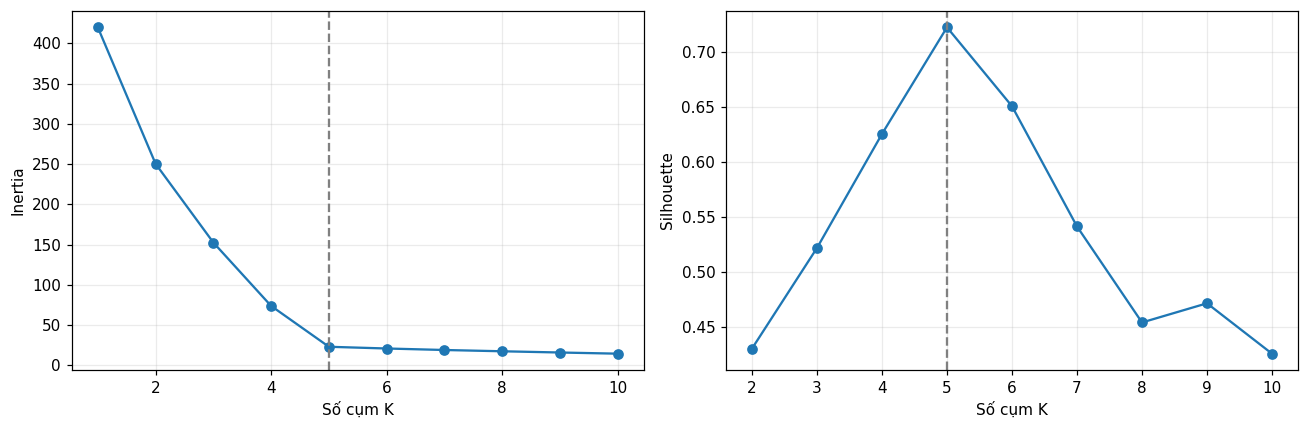

In [4]:
bang_k=[]
for k in range(1,11):
    m=KMeans(n_clusters=k,n_init=10,random_state=0).fit(Xs)
    bang_k.append({'K':k,'inertia':m.inertia_,'silhouette':silhouette_score(Xs,m.labels_) if k>1 else np.nan})
bang_k=pd.DataFrame(bang_k); bang_k['giam_inertia']=-bang_k['inertia'].diff()
k_tot=int(bang_k.loc[bang_k['silhouette'].idxmax(),'K'])
display(bang_k.round(4)); print('K tốt nhất theo silhouette:',k_tot)
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].plot(bang_k['K'],bang_k['inertia'],'o-'); axes[0].set_ylabel('Inertia')
axes[1].plot(bang_k['K'],bang_k['silhouette'],'o-'); axes[1].set_ylabel('Silhouette')
for ax in axes: ax.set_xlabel('Số cụm K'); ax.axvline(k_tot,linestyle='--',color='gray')
plt.tight_layout(); luu_hinh('hinh3_chon_k.png')

**Nhận xét từ lần chạy đã kiểm tra:** Cả khuỷu tay và silhouette ủng hộ **K=5**: inertia **23.0167**, silhouette **0.7227**; tăng K=6 chỉ giảm inertia 2.1428 nhưng silhouette giảm còn 0.6508.

## Bước 4 — Ba cái bẫy (Mục 5, `k4`)

Đổi thu nhập sang nghìn đồng rồi quên chuẩn hoá khiến thu nhập lấn át chi tiêu. Khởi tạo ngẫu
nhiên một lần dễ rơi vào nghiệm xấu. Cụm hình cong như vầng trăng không phù hợp cách chia thành
vùng gần tâm của K-Means. Không so trị số inertia giữa các không gian có thang đo khác nhau.

Tâm khi quên chuẩn hoá, đổi về đơn vị gốc:


,thu_nhap,diem_chi_tieu
0,6.09,52.50
1,27.78,52.94
2,17.36,49.81
3,9.56,41.95
4,31.90,52.42


Inertia của 20 khởi tạo: [ 23.   23.   23.   23.   23.   23.   23.   23.   23.   23.   72.4  73.6
  73.7  73.7  84.   84.2  84.2 116.6 117.4 118.2]
Số nghiệm tệ hơn mức 23.0 (làm tròn 1 chữ số): 10
hai_vang_trang.csv: 300 dòng, 3 cột; không thiếu giá trị ở cột dùng
Khớp tốt nhất sau hoán đổi 2 nhãn: 0.75


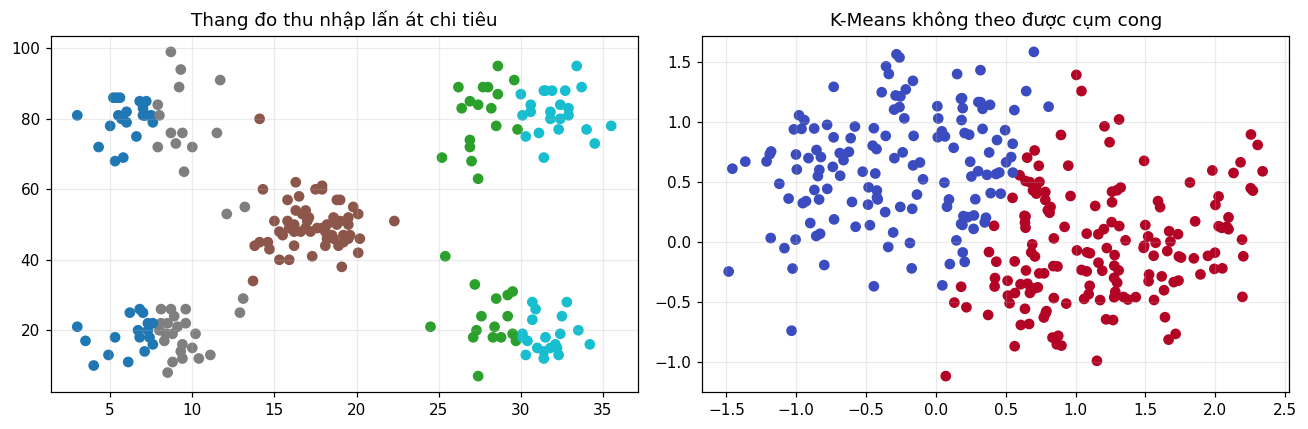

In [5]:
X_nghin=X.copy(); X_nghin['thu_nhap']*=1000
km_tho=KMeans(n_clusters=5,n_init=10,random_state=0).fit(X_nghin)
tam_tho=km_tho.cluster_centers_.copy(); tam_tho[:,0]/=1000
print('Tâm khi quên chuẩn hoá, đổi về đơn vị gốc:'); display(pd.DataFrame(tam_tho,columns=cot).round(2))
inertia_20=[KMeans(n_clusters=5,init='random',n_init=1,random_state=rs).fit(Xs).inertia_ for rs in range(20)]
print('Inertia của 20 khởi tạo:',np.round(sorted(inertia_20),1))
print('Số nghiệm tệ hơn mức 23.0 (làm tròn 1 chữ số):',sum(np.round(inertia_20,1)>23.0))
trang=doc_csv('hai_vang_trang.csv',['x1','x2','nhan']); Xt=trang[['x1','x2']]
km_trang=KMeans(n_clusters=2,n_init=10,random_state=0).fit(Xt)
khop=(km_trang.labels_==trang['nhan']).mean()
print('Khớp tốt nhất sau hoán đổi 2 nhãn:',max(khop,1-khop))
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].scatter(X['thu_nhap'],X['diem_chi_tieu'],c=km_tho.labels_,cmap='tab10'); axes[0].set_title('Thang đo thu nhập lấn át chi tiêu')
axes[1].scatter(Xt['x1'],Xt['x2'],c=km_trang.labels_,cmap='coolwarm_r'); axes[1].set_title('K-Means không theo được cụm cong')
plt.tight_layout(); luu_hinh('hinh4_ba_cai_bay.png')

**Nhận xét từ lần chạy đã kiểm tra:** 10/20 khởi tạo ngẫu nhiên rơi vào nghiệm xấu hơn mức 23.0; trên vầng trăng, K-Means chỉ khớp **0.7500** sau hoán đổi nhãn. Chuẩn hoá không chữa được giả định hình dạng cụm không phù hợp.

## Bước 5 — Nén màu ảnh (Mục 6, `k5`)

Mỗi điểm ảnh RGB là một điểm trong không gian 3 chiều. Học bảng màu trên 5.000 pixel lấy ngẫu
nhiên, gán toàn ảnh về tâm màu gần nhất. Số bit chỉ số lý tưởng là ceil(log₂K), chưa tính bảng màu,
header hoặc cơ chế nén tệp. Giảm số màu **không đồng nghĩa** tệp PNG giảm đúng 24/bit lần.

Kích thước ảnh: (427, 640, 3) ; số màu: 96615


,K,bit_chi_so,ti_so_ly_tuong,MAE_muc_sang
0,4,2,12.0,17.411
1,16,4,6.0,7.975
2,64,6,4.0,4.539


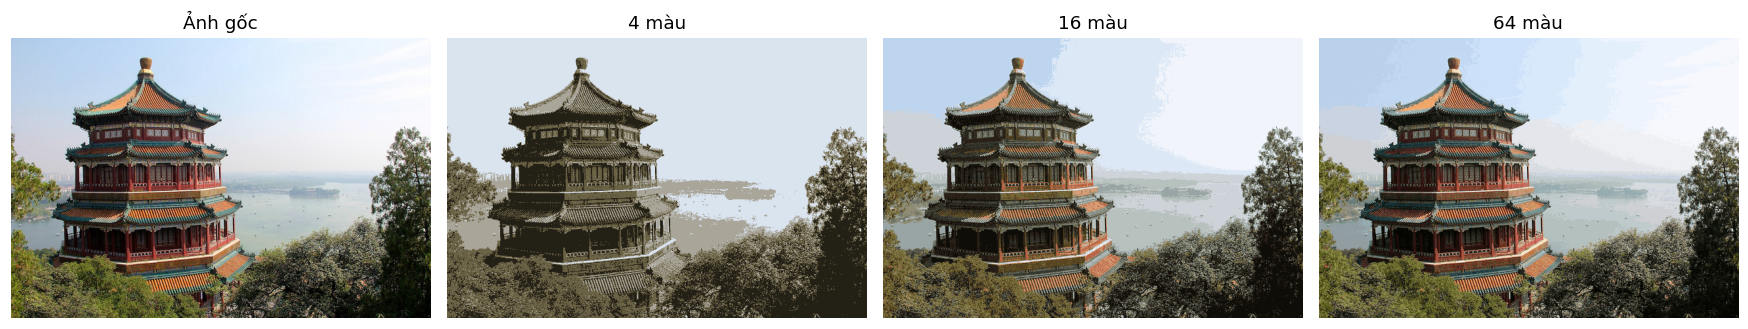

In [6]:
anh=load_sample_image('china.jpg')
cao,rong,_=anh.shape; diem=anh.reshape(-1,3)/255.
rng=np.random.default_rng(0); mau=diem[rng.choice(len(diem),5000,replace=False)]
print('Kích thước ảnh:',anh.shape,'; số màu:',len(np.unique(anh.reshape(-1,3),axis=0)))
anh_nen={}; bang_anh=[]
fig,axes=plt.subplots(1,4,figsize=(16,5))
axes[0].imshow(anh); axes[0].set_title('Ảnh gốc')
for ax,k in zip(axes[1:],[4,16,64]):
    m=KMeans(n_clusters=k,n_init=4,random_state=0).fit(mau)
    moi=m.cluster_centers_[m.predict(diem)].reshape(anh.shape); anh_nen[k]=moi
    bit=int(np.ceil(np.log2(k)))
    bang_anh.append({'K':k,'bit_chi_so':bit,'ti_so_ly_tuong':24/bit,'MAE_muc_sang':abs(moi-anh/255.).mean()*255})
    ax.imshow(moi); ax.set_title(f'{k} màu')
for ax in axes: ax.axis('off')
display(pd.DataFrame(bang_anh).round(3)); plt.tight_layout(); luu_hinh('hinh5_nen_mau.png')

**Nhận xét từ lần chạy đã kiểm tra:** Ảnh mẫu có 96.615 màu. Với 16 màu, sai lệch trung bình **7.975 mức sáng** trên thang 0–255; giảm số màu làm mất chi tiết chuyển sắc. Tỷ số 6 lần chỉ là lý thuyết mã chỉ số màu, chưa phải dung lượng PNG.

---
# Phần B — Bài tập
## Bài tập 1 — Tự tính silhouette bằng NumPy

Tính trên **dữ liệu đã chuẩn hoá** và đúng nhãn K=5 ở phần A. Loại điểm i khỏi trung bình a.
Với cụm đơn điểm, quy ước s=0 như sklearn; b là trung bình theo từng cụm khác, không phải
khoảng cách tới điểm gần nhất hay tâm gần nhất.

Silhouette trung bình tự tính/sklearn: 0.7227055107668372 0.7227055107668373
Khách có s nhỏ nhất (chỉ số dòng 0-based): 113 a,b,s: [0.91775835 0.94475046 0.02857062]


,tuoi,thu_nhap,diem_chi_tieu,cum
113,38,25.4,41,2


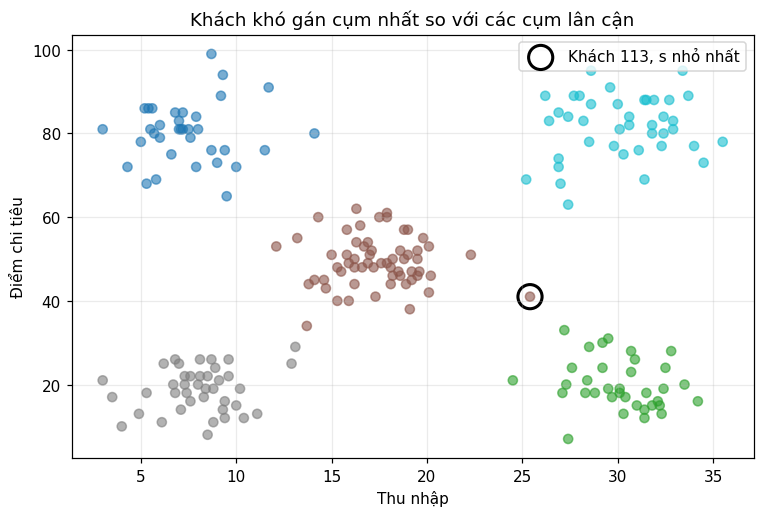

In [7]:
def silhouette_mot_diem(X,nhan,i):
    X=np.asarray(X,dtype=float); nhan=np.asarray(nhan)
    if X.ndim!=2 or nhan.shape!=(len(X),) or not 0<=i<len(X):
        raise ValueError('Sai kích thước hoặc chỉ số điểm.')
    cac_cum=np.unique(nhan)
    if not 2<=len(cac_cum)<len(X): raise ValueError('Cần từ 2 đến n-1 cụm.')
    d=np.sqrt(((X-X[i])**2).sum(axis=1))
    cung=(nhan==nhan[i]); cung[i]=False
    a=float(d[cung].mean()) if cung.any() else 0.
    b=min(float(d[nhan==k].mean()) for k in cac_cum if k!=nhan[i])
    s=(b-a)/max(a,b) if cung.any() and max(a,b)>0 else 0.
    return a,b,s


tu_tinh=np.array([silhouette_mot_diem(Xs,km5.labels_,i) for i in range(len(Xs))])
sk=silhouette_samples(Xs,km5.labels_)
assert np.allclose(tu_tinh[:,2],sk,atol=1e-10)
assert silhouette_mot_diem([[0],[1],[2]],[0,1,1],0)[2]==0
i_xau=int(tu_tinh[:,2].argmin())
print('Silhouette trung bình tự tính/sklearn:',tu_tinh[:,2].mean(),silhouette_score(Xs,km5.labels_))
print('Khách có s nhỏ nhất (chỉ số dòng 0-based):',i_xau,'a,b,s:',tu_tinh[i_xau])
display(khach.iloc[[i_xau]].assign(cum=km5.labels_[i_xau]))
plt.figure(); plt.scatter(X['thu_nhap'],X['diem_chi_tieu'],c=km5.labels_,cmap='tab10',alpha=.6)
plt.scatter(X.iloc[i_xau,0],X.iloc[i_xau,1],s=250,facecolors='none',edgecolors='black',linewidths=2,label=f'Khách {i_xau}, s nhỏ nhất')
plt.xlabel('Thu nhập'); plt.ylabel('Điểm chi tiêu'); plt.legend(); plt.title('Khách khó gán cụm nhất so với các cụm lân cận')
luu_hinh('hinh6_khach_silhouette_nho_nhat.png')

**Nhận xét từ lần chạy đã kiểm tra:** Silhouette NumPy **0.7227055108** khớp sklearn đến sai số dấu phẩy động. Khách dòng **113 (đếm từ 0)** có thu nhập **25.4**, điểm chi tiêu **41**, s nhỏ nhất **0.02857**; a≈0.9178 và b≈0.9448 gần nhau. Khách ở rìa phải của nhóm trung bình, gần vùng các nhóm thu nhập cao.

**Giải thích:** khách có s nhỏ thường ở rìa cụm hoặc gần cụm khác. Vị trí được đánh dấu trên
hình cùng hệ trục với Hình 3 của đề; cần nhìn cả khoảng cách đã chuẩn hoá, không chỉ khoảng cách
trên hình theo đơn vị gốc.

## Bài tập 2 — Thêm tuổi, chọn lại K

Chuẩn hoá cả ba cột, chọn K=2..10 theo silhouette. So tâm ở đơn vị gốc; không ghép mã cụm hai
lần phân nhóm theo số thứ tự vì mã cụm không có ý nghĩa ổn định.

In [8]:
cot3=['tuoi','thu_nhap','diem_chi_tieu']; sc3=StandardScaler().fit(khach[cot3]); X3=sc3.transform(khach[cot3])
bang_k3=[]
for k in range(2,11):
    m=KMeans(n_clusters=k,n_init=10,random_state=0).fit(X3)
    bang_k3.append({'K':k,'silhouette':silhouette_score(X3,m.labels_),'inertia':m.inertia_})
bang_k3=pd.DataFrame(bang_k3); k3_tot=int(bang_k3.loc[bang_k3['silhouette'].idxmax(),'K'])
km3=KMeans(n_clusters=k3_tot,n_init=10,random_state=0).fit(X3)
display(bang_k3.round(4)); print('K tốt nhất khi có tuổi:',k3_tot)
tam3=pd.DataFrame(sc3.inverse_transform(km3.cluster_centers_),columns=cot3)
tam3['so_khach']=np.bincount(km3.labels_); display(tam3.sort_values('thu_nhap').round(2))
print('Tâm hai cột để so nội dung nhóm:'); display(tam_goc.sort_values('thu_nhap').round(2))
print('Bảng giao hai cách chia, không giả định mã cụm tương ứng:')
display(pd.crosstab(pd.Series(km5.labels_,name='cum_2_cot'),pd.Series(km3.labels_,name='cum_3_cot')))

,K,silhouette,inertia
0,2,0.3730,373.5058
1,3,0.4220,271.8062
2,4,0.4558,187.2230
3,5,0.4808,133.4585
4,6,0.4760,108.8831
5,7,0.4627,92.9637
6,8,0.4596,80.6993
7,9,0.4622,69.5808
8,10,0.4573,58.4004


K tốt nhất khi có tuổi: 5


,tuoi,thu_nhap,diem_chi_tieu,so_khach
0,44.88,8.04,18.85,40
1,25.13,8.48,77.56,39
4,41.65,17.58,49.18,57
2,42.86,30.13,19.97,35
3,32.08,30.28,82.00,39


Tâm hai cột để so nội dung nhóm:


,thu_nhap,diem_chi_tieu,so_khach,tuoi_tb
0,7.48,80.20,35,24.94
3,8.04,18.85,40,44.88
2,17.39,49.30,60,40.45
1,30.13,19.97,35,42.86
4,30.21,81.53,40,32.62


Bảng giao hai cách chia, không giả định mã cụm tương ứng:


cum_3_cot,0,1,2,3,4
cum_2_cot,,,,,
0,0,35,0,0,0
1,0,0,35,0,0
2,0,4,0,0,56
3,40,0,0,0,0
4,0,0,0,39,1


**Nhận xét từ lần chạy đã kiểm tra:** Thêm tuổi vẫn chọn **K=5**, silhouette **0.4808** trong không gian ba cột. Nhóm thấp/chi cao đổi từ 35 lên 39 khách, nhóm trung bình từ 60 xuống 57, nhóm cao/chi cao từ 40 xuống 39. Tuổi làm đổi cách đo tương đồng nên một số khách đổi nhóm; không so hai trị số silhouette như cùng một mục tiêu hình học.

## Bài tập 3 — K-Means++ và khởi tạo ngẫu nhiên

Mỗi cách chạy đúng 50 seed 0..49, `n_init=1`. Đếm đạt inertia **23.0 sau làm tròn 1 chữ số**
như số đề, tránh so bằng tuyệt đối với 23.0 trên số thực. K-Means++ giúp chọn tâm ban đầu cách
xa nhau, nhưng không bảo đảm tìm nghiệm toàn cục; nhiều lần khởi tạo vẫn hữu ích.

,so_lan_dat,tong_lan,inertia_tb,inertia_max
init,,,,
k-means++,50,50,23.0167,23.0167
random,30,50,53.2914,204.0456


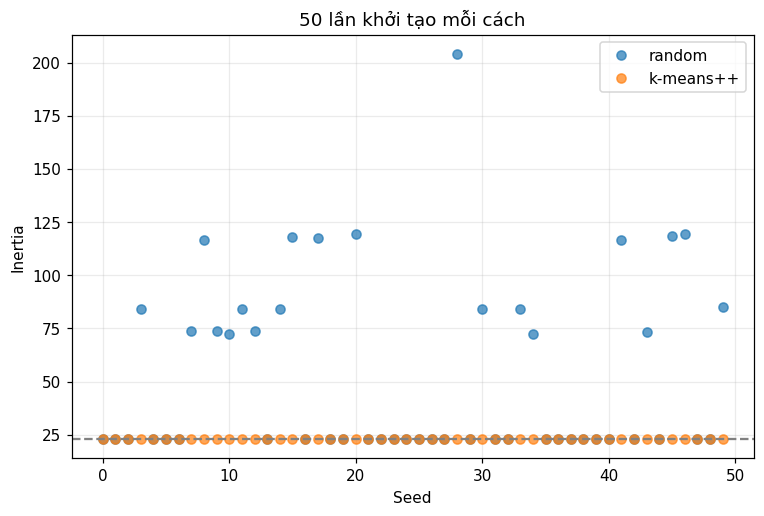

In [9]:
bang_init=[]
for cach in ['random','k-means++']:
    for rs in range(50):
        m=KMeans(n_clusters=5,init=cach,n_init=1,random_state=rs).fit(Xs)
        bang_init.append({'init':cach,'seed':rs,'inertia':m.inertia_,'dat_23':round(m.inertia_,1)==23.0})
bang_init=pd.DataFrame(bang_init)
display(bang_init.groupby('init').agg(so_lan_dat=('dat_23','sum'),tong_lan=('dat_23','size'),
                                     inertia_tb=('inertia','mean'),inertia_max=('inertia','max')).round(4))
plt.figure()
for cach in ['random','k-means++']:
    phan=bang_init[bang_init['init']==cach]; plt.plot(phan['seed'],phan['inertia'],'o',alpha=.7,label=cach)
plt.axhline(km5.inertia_,color='gray',linestyle='--'); plt.xlabel('Seed'); plt.ylabel('Inertia'); plt.legend()
plt.title('50 lần khởi tạo mỗi cách'); luu_hinh('hinh7_so_khoi_tao.png')

**Nhận xét từ lần chạy đã kiểm tra:** Khởi tạo **k-means++ đạt 50/50**, random **30/50** nghiệm làm tròn inertia 23.0. K-Means++ đáng tin hơn trong 50 seed này; không suy thành bảo đảm tuyệt đối cho dữ liệu khác.

## Bài tập 4 — Lưu ảnh nén và đọc thêm ảnh từ repo

Lưu ảnh mẫu 427×640×3 thành `anh_goc.png`, `anh_16_mau.png`, rồi đo byte thật.
Theo lựa chọn của người dùng, ảnh bổ sung là biểu đồ `hinh11_permutation_importance.png` của
Lab5 trong repo, **không phải ảnh cá nhân**. Phần này minh họa đọc ảnh bằng `plt.imread`, bỏ alpha
nếu có, nén 16 màu và lưu kết quả. Có thể đổi `DUONG_DAN_ANH_THEM` sang ảnh cá nhân khi cần.

PNG gốc: 550154 bytes; 16 màu: 134387 bytes; tỷ số: 4.093803716133257
Tỷ số tệp thực tế khác tỷ số 6 lần của chỉ số màu lý tưởng.


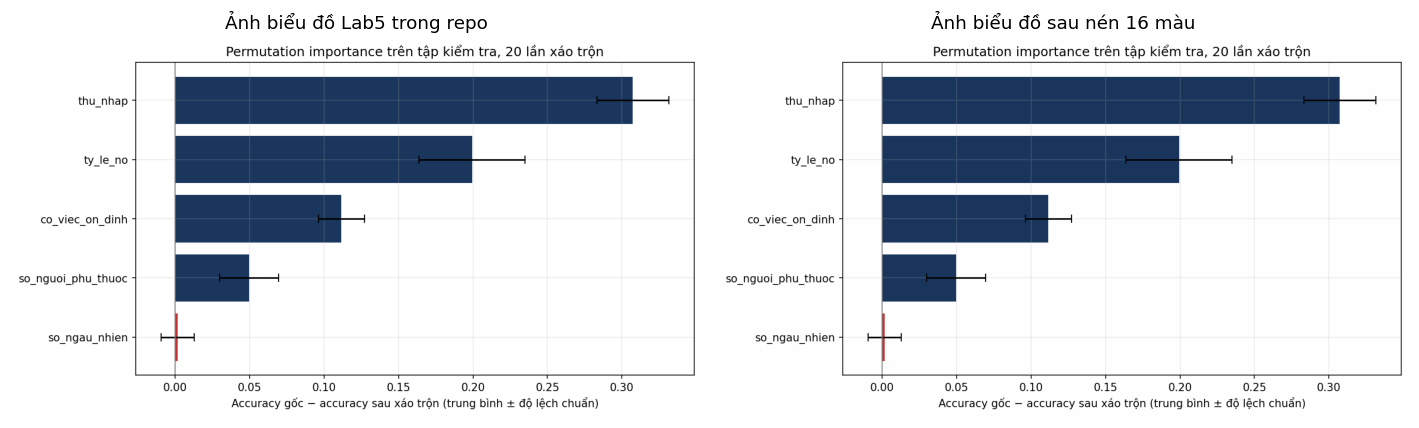

In [10]:
assert anh_nen[16].shape==(427,640,3)
plt.imsave(THU_MUC_ANH/'anh_goc.png',anh)
plt.imsave(THU_MUC_ANH/'anh_16_mau.png',anh_nen[16])
goc_byte=(THU_MUC_ANH/'anh_goc.png').stat().st_size
nen_byte=(THU_MUC_ANH/'anh_16_mau.png').stat().st_size
print('PNG gốc:',goc_byte,'bytes; 16 màu:',nen_byte,'bytes; tỷ số:',goc_byte/nen_byte)
print('Tỷ số tệp thực tế khác tỷ số 6 lần của chỉ số màu lý tưởng.')

GOC_REPO=THU_MUC_LAB.resolve().parent
DUONG_DAN_ANH_THEM=GOC_REPO/'05.DecisionTree_RandomForest/images/hinh11_permutation_importance.png'


def nen_anh_tu_tep(duong_dan,so_mau=16):
    a=plt.imread(duong_dan)
    if a.ndim==2: a=np.repeat(a[:,:,None],3,axis=2)
    if a.ndim!=3 or a.shape[2] not in [3,4]: raise ValueError('Cần ảnh xám, RGB hoặc RGBA.')
    a=a[:,:,:3]  # Bỏ alpha theo yêu cầu; ảnh mẫu trong repo có nền trắng.
    a=a.astype(float)/np.iinfo(a.dtype).max if np.issubdtype(a.dtype,np.integer) else a.astype(float)
    a=np.clip(a,0,1); px=a.reshape(-1,3)
    rng=np.random.default_rng(0); tap=px[rng.choice(len(px),min(5000,len(px)),replace=False)]
    m=KMeans(n_clusters=so_mau,n_init=4,random_state=0).fit(tap)
    moi=m.cluster_centers_[m.predict(px)].reshape(a.shape)
    return a,moi


# Không có ảnh bổ sung khi chỉ tải riêng Lab8: phần mẫu china.jpg vẫn chạy được.
if DUONG_DAN_ANH_THEM.is_file():
    anh_them,nen_them=nen_anh_tu_tep(DUONG_DAN_ANH_THEM)
    plt.imsave(THU_MUC_ANH/'anh_repo_16_mau.png',nen_them)
    fig,axes=plt.subplots(1,2,figsize=(13,5))
    for ax,a,ten in zip(axes,[anh_them,nen_them],['Ảnh biểu đồ Lab5 trong repo','Ảnh biểu đồ sau nén 16 màu']):
        ax.imshow(a); ax.set_title(ten); ax.axis('off')
    plt.tight_layout(); luu_hinh('hinh8_anh_bo_sung_tu_repo.png')
else:
    print('Không thấy ảnh Lab5. Đổi DUONG_DAN_ANH_THEM sang ảnh có sẵn để chạy phần bổ sung.')

**Nhận xét từ lần chạy đã kiểm tra:** PNG gốc **550154 byte**, PNG 16 màu **134387 byte**, nhỏ hơn khoảng **4.09 lần**, không phải 6 lần. Phần ảnh bổ sung đã đọc và nén biểu đồ Lab5 theo lựa chọn của người dùng; lưu thêm `anh_repo_16_mau.png`.

## Bài tập 5 — DBSCAN trên hai vầng trăng

Giữ toạ độ gốc như đề, min_samples=5, eps=0.2,0.3,0.4. Không tính nhãn -1 là một cụm;
đó là điểm nhiễu. Dùng ARI để so hậu nghiệm với nhãn thật mà không phụ thuộc việc đổi tên cụm.
Eps quá nhỏ tạo nhiều cụm/nhiễu; quá lớn có thể nối các cụm.

,eps,so_cum,diem_nhieu,ARI
0,0.2,1,40,-0.0014
1,0.3,1,10,0.0012
2,0.4,1,3,-0.0001


ARI K-Means để so: 0.24749231217340997


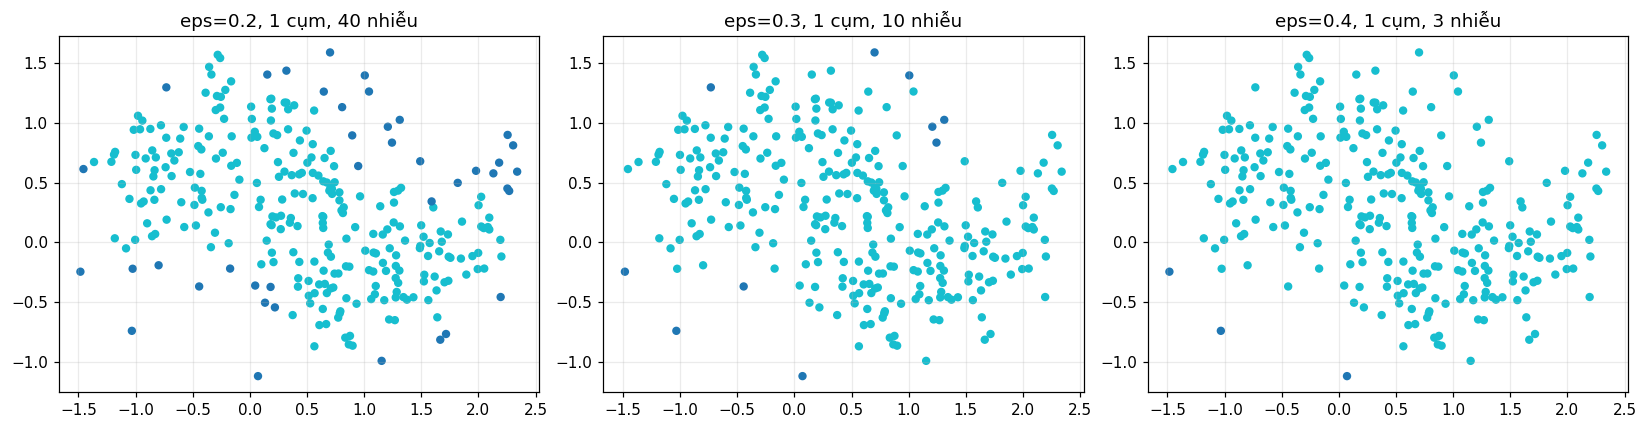

In [11]:
bang_db=[]; fig,axes=plt.subplots(1,3,figsize=(15,4))
for ax,e in zip(axes,[.2,.3,.4]):
    nhan=DBSCAN(eps=e,min_samples=5).fit_predict(Xt)
    so_cum=len(set(nhan)-{-1}); nhieu=int((nhan==-1).sum())
    bang_db.append({'eps':e,'so_cum':so_cum,'diem_nhieu':nhieu,'ARI':adjusted_rand_score(trang['nhan'],nhan)})
    ax.scatter(Xt['x1'],Xt['x2'],c=nhan,cmap='tab10',s=20); ax.set_title(f'eps={e}, {so_cum} cụm, {nhieu} nhiễu')
display(pd.DataFrame(bang_db).round(4))
print('ARI K-Means để so:',adjusted_rand_score(trang['nhan'],km_trang.labels_))
plt.tight_layout(); luu_hinh('hinh9_dbscan.png')

**Nhận xét từ lần chạy đã kiểm tra:** **Không có eps nào trong ba giá trị đề cho tách tốt hơn K-Means** trên dữ liệu hiện có: eps 0.2/0.3/0.4 đều cho **1 cụm**, số nhiễu lần lượt **40/10/3**, ARI quanh 0. K-Means có ARI≈0.2475. Các điểm nhiễu và vùng nối đủ dày làm DBSCAN nối hai vầng trăng; không được mặc định DBSCAN luôn tốt cho hình cong.

## Bài tập 6 — Phân cụm chữ số, sau đó mới xem nhãn

K=10 trên 64 độ sáng gốc như yêu cầu; không đưa nhãn chữ số vào fit. Mỗi tâm là một ảnh trung
bình, không phải một ảnh thật. Bảng chéo cho biết những chữ số nào cùng vào một cụm.

cum,0,1,2,3,4,5,6,7,8,9
chu_so_that,,,,,,,,,,
0,176,0,0,0,0,0,2,0,0,0
1,0,100,0,54,1,2,0,1,0,24
2,1,8,3,2,13,0,0,0,2,148
3,0,7,7,0,154,0,0,2,13,0
4,0,2,11,3,0,0,165,0,0,0
5,0,0,0,0,2,1,2,136,41,0
6,1,3,0,0,0,177,0,0,0,0
7,0,2,174,2,0,0,0,1,0,0
8,0,100,5,6,2,2,0,4,52,3


,cum_chinh,ty_le_vao_cum_chinh
chu_so_that,,
0,0,0.9888
1,1,0.5495
2,9,0.8362
3,4,0.8415
4,6,0.9116
5,7,0.7473
6,5,0.9779
7,2,0.9721
8,1,0.5747


Thành phần chính của từng cụm:
Cụm 0 : {0: 176, 2: 1, 6: 1}
Cụm 1 : {1: 100, 8: 100, 2: 8}
Cụm 2 : {7: 174, 4: 11, 9: 8}
Cụm 3 : {1: 54, 9: 20, 8: 6}
Cụm 4 : {3: 154, 2: 13, 9: 6}
Cụm 5 : {6: 177, 1: 2, 8: 2}
Cụm 6 : {4: 165, 0: 2, 5: 2}
Cụm 7 : {5: 136, 9: 6, 8: 4}
Cụm 8 : {9: 139, 8: 52, 5: 41}
Cụm 9 : {2: 148, 1: 24, 8: 3}


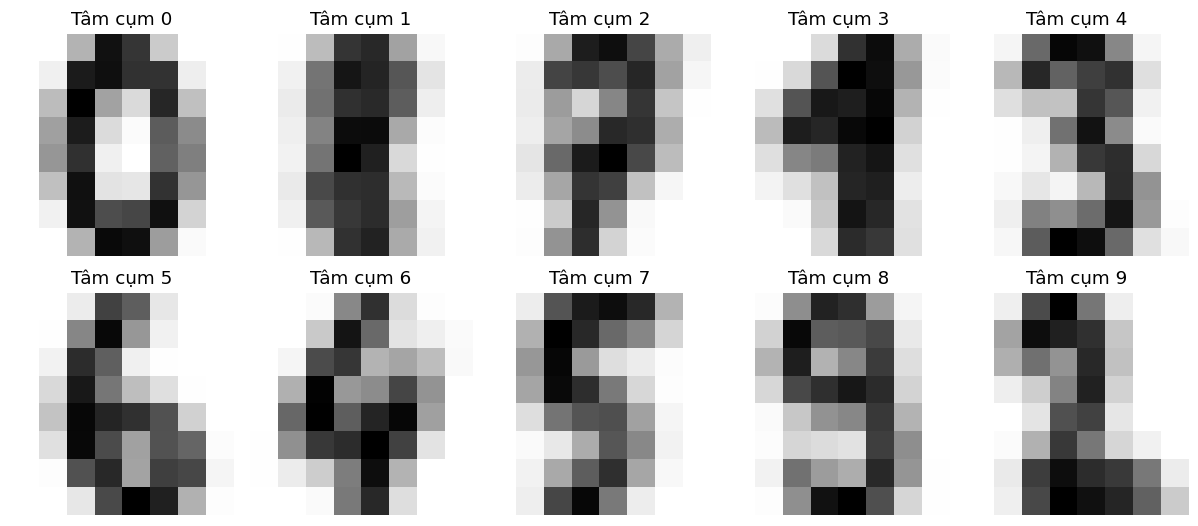

In [12]:
Xd,yd=load_digits(return_X_y=True)
km_digits=KMeans(n_clusters=10,n_init=10,random_state=0).fit(Xd)
bang_cheo=pd.crosstab(pd.Series(yd,name='chu_so_that'),pd.Series(km_digits.labels_,name='cum'))
display(bang_cheo)
phan_bo=bang_cheo.div(bang_cheo.sum(axis=1),axis=0)
display(pd.DataFrame({'cum_chinh':phan_bo.idxmax(axis=1),'ty_le_vao_cum_chinh':phan_bo.max(axis=1)}).round(4))
print('Thành phần chính của từng cụm:')
for c in bang_cheo.columns:
    print('Cụm',c,':',bang_cheo[c].sort_values(ascending=False).head(3).to_dict())
fig,axes=plt.subplots(2,5,figsize=(11,5))
for i,ax in enumerate(axes.flat):
    ax.imshow(km_digits.cluster_centers_[i].reshape(8,8),cmap='gray_r'); ax.set_title(f'Tâm cụm {i}'); ax.axis('off')
plt.tight_layout(); luu_hinh('hinh10_tam_cum_chu_so.png')

**Nhận xét từ lần chạy đã kiểm tra:** Các chữ số **0,6,7** khá gọn: lần lượt **98.88%,97.79%,97.21%** vào cụm chính. Cụm 1 chứa **100 số 1 và 100 số 8**; cụm 8 trộn 9/8/5 với 139/52/41 ảnh. Đây là nhóm theo hình dáng pixel, không phải mô hình được học với nhãn để phân loại.

**Kết luận:** chuẩn hoá và nhiều lần khởi tạo giúp K-Means đáng tin hơn; K và hình dạng cụm vẫn
phải phù hợp dữ liệu. Silhouette tốt không chứng minh nhóm có ý nghĩa nghiệp vụ; mã cụm cũng
không phải nhãn phân loại, đặc biệt với các chữ số có nhiều kiểu viết.